# Notebook 01 – Thu thập, Khảo sát dữ liệu & Phân tích khám phá (EDA)

**Nội dung thực hiện:**
1. **Thu thập & Quy mô:** Đọc dữ liệu gốc từ `data/raw/metro_interstate_traffic_volume.csv` (48.204 dòng × 9 cột, biến mục tiêu `traffic_volume`).
2. **Khảo sát dữ liệu:** Kiểm tra giai đoạn đo (2012–2018), tính liên tục theo giờ, tỷ lệ khuyết (`holiday`), ngoại lai vật lý (`temp = 0K`, `rain_1h = 9831.3 mm`) và dòng trùng mốc giờ `date_time`.
3. **Phân tích khám phá (EDA):** Trực quan hóa phân bố lưu lượng, quy luật theo giờ (ngày thường vs cuối tuần), Thứ × Giờ, thời tiết và ngày lễ.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

RAW_DIR = os.path.join("..", "data", "raw")
RAW_PATH = os.path.join(RAW_DIR, "metro_interstate_traffic_volume.csv")
os.makedirs(RAW_DIR, exist_ok=True)

print("pandas:", pd.__version__, "| numpy:", np.__version__)
print("File dữ liệu gốc tại:", os.path.abspath(RAW_PATH))

pandas: 3.0.3 | numpy: 2.4.6
File dữ liệu gốc tại: d:\big data\btl_nhóm_3\data\raw\metro_interstate_traffic_volume.csv


In [2]:
df = pd.read_csv(RAW_PATH)
df["date_time"] = pd.to_datetime(df["date_time"])

print("Số bản ghi (dòng):", df.shape[0])
print("Số cột           :", df.shape[1])
print("Danh sách cột    :", df.columns.tolist())
df.head(10)

Số bản ghi (dòng): 48204
Số cột           : 9
Danh sách cột    : ['holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main', 'weather_description', 'date_time', 'traffic_volume']


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918
5,NaN,291.72,0.0,0.0,1,Clear,sky is clear,2012-10-02 14:00:00,5181
6,NaN,293.17,0.0,0.0,1,Clear,sky is clear,2012-10-02 15:00:00,5584
7,NaN,293.86,0.0,0.0,1,Clear,sky is clear,2012-10-02 16:00:00,6015
8,NaN,294.14,0.0,0.0,20,Clouds,few clouds,2012-10-02 17:00:00,5791
9,NaN,293.10,0.0,0.0,20,Clouds,few clouds,2012-10-02 18:00:00,4770


In [3]:
# 3. Kiểm tra khoảng thời gian đo & độ liên tục của giờ
t_min, t_max = df["date_time"].min(), df["date_time"].max()
so_gio_ly_thuyet = int((t_max - t_min) / pd.Timedelta(hours=1)) + 1

print("Thời điểm bắt đầu :", t_min)
print("Thời điểm kết thúc:", t_max)
print("Độ dài giai đoạn  :", round((t_max - t_min).days / 365.25, 2), "năm")
print("Số giờ lý thuyết nếu đo liên tục:", so_gio_ly_thuyet)
print("Số mốc giờ khác nhau thực tế có:", df["date_time"].nunique())
print("Số giờ bị thiếu   :", so_gio_ly_thuyet - df["date_time"].nunique())

print("\nSố bản ghi theo từng năm:")
print(df["date_time"].dt.year.value_counts().sort_index().to_string())

Thời điểm bắt đầu : 2012-10-02 09:00:00
Thời điểm kết thúc: 2018-09-30 23:00:00
Độ dài giai đoạn  : 5.99 năm
Số giờ lý thuyết nếu đo liên tục: 52551
Số mốc giờ khác nhau thực tế có: 40575
Số giờ bị thiếu   : 11976

Số bản ghi theo từng năm:
date_time
2012     2559
2013     8573
2014     4839
2015     4373
2016     9306
2017    10605
2018     7949


In [4]:
# 4. Kiểm tra kiểu dữ liệu & Giá trị khuyết (Missing Values)
info_table = pd.DataFrame({
    "kieu_du_lieu": df.dtypes.astype(str),
    "so_gia_tri_khuyet": df.isna().sum(),
    "ty_le_khuyet_%": (df.isna().mean() * 100).round(2),
    "so_gia_tri_khac_nhau": df.nunique(),
})
display(info_table)

print("\nSố dòng có tên ngày lễ:", df["holiday"].notna().sum())
print(df["holiday"].value_counts().to_string())
print("\nGiờ trong ngày của các dòng có nhãn lễ:", sorted(df.loc[df["holiday"].notna(), "date_time"].dt.hour.unique().tolist()))

,kieu_du_lieu,so_gia_tri_khuyet,ty_le_khuyet_%,so_gia_tri_khac_nhau
holiday,str,48143,99.87,11
temp,float64,0,0.00,5843
rain_1h,float64,0,0.00,372
snow_1h,float64,0,0.00,12
clouds_all,int64,0,0.00,60
weather_main,str,0,0.00,11
weather_description,str,0,0.00,38
date_time,datetime64[us],0,0.00,40575
traffic_volume,int64,0,0.00,6704



Số dòng có tên ngày lễ: 61
holiday
Labor Day                    7
Thanksgiving Day             6
Christmas Day                6
New Years Day                6
Martin Luther King Jr Day    6
Columbus Day                 5
Veterans Day                 5
Washingtons Birthday         5
Memorial Day                 5
Independence Day             5
State Fair                   5

Giờ trong ngày của các dòng có nhãn lễ: [0]


In [5]:
# 5. Thống kê mô tả & Phát hiện ngoại lai vật lý (Outliers)
desc_num = df.describe(include=[np.number]).T
desc_num["temp_min_doC"] = np.nan
desc_num.loc["temp", "temp_min_doC"] = df["temp"].min() - 273.15
display(desc_num.round(2))

print("Số dòng temp = 0 Kelvin (≈ -273.15°C, lỗi cảm biến):", (df["temp"] <= 0).sum())
print("Số dòng rain_1h >= 500 mm/giờ (mưa phi thực tế)    :", (df["rain_1h"] >= 500).sum())

,count,mean,std,min,25%,50%,75%,max,temp_min_doC
temp,48204.0,281.21,13.34,0.0,272.16,282.45,291.81,310.07,-273.15
rain_1h,48204.0,0.33,44.79,0.0,0.00,0.00,0.00,9831.30,NaN
snow_1h,48204.0,0.00,0.01,0.0,0.00,0.00,0.00,0.51,NaN
clouds_all,48204.0,49.36,39.02,0.0,1.00,64.00,90.00,100.00,NaN
traffic_volume,48204.0,3259.82,1986.86,0.0,1193.00,3380.00,4933.00,7280.00,NaN


Số dòng temp = 0 Kelvin (≈ -273.15°C, lỗi cảm biến): 10
Số dòng rain_1h >= 500 mm/giờ (mưa phi thực tế)    : 1


In [6]:
# 6. Kiểm tra dữ liệu trùng lặp (Trùng cả 9 cột vs Trùng mốc giờ date_time)
so_trung_hoan_toan = df.duplicated().sum()
so_trung_date_time = df.duplicated(subset=["date_time"]).sum()

print("Tổng số dòng                         :", len(df))
print("Số dòng TRÙNG HOÀN TOÀN (cả 9 cột)    :", so_trung_hoan_toan)
print("Số dòng TRÙNG MỐC THỜI GIAN date_time :", so_trung_date_time)
print("Số mốc giờ duy nhất                  :", df["date_time"].nunique())

dem_theo_gio = df["date_time"].value_counts()
gio_vi_du = dem_theo_gio.index[0]
print(f"\nVí dụ mốc giờ lặp nhiều dòng nhất ({gio_vi_du} - {dem_theo_gio.iloc[0]} dòng):")
df[df["date_time"] == gio_vi_du]

Tổng số dòng                         : 48204
Số dòng TRÙNG HOÀN TOÀN (cả 9 cột)    : 17
Số dòng TRÙNG MỐC THỜI GIAN date_time : 7629
Số mốc giờ duy nhất                  : 40575

Ví dụ mốc giờ lặp nhiều dòng nhất (2013-04-18 22:00:00 - 6 dòng):


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
5249,NaN,274.79,0.0,0.0,90,Mist,mist,2013-04-18 22:00:00,1532
5250,NaN,274.79,0.0,0.0,90,Drizzle,light intensity drizzle,2013-04-18 22:00:00,1532
5251,NaN,274.79,0.0,0.0,90,Rain,light rain,2013-04-18 22:00:00,1532
5252,NaN,274.79,0.0,0.0,90,Rain,moderate rain,2013-04-18 22:00:00,1532
5253,NaN,274.79,0.0,0.0,90,Snow,heavy snow,2013-04-18 22:00:00,1532
5254,NaN,274.79,0.0,0.0,90,Snow,snow,2013-04-18 22:00:00,1532


Đã lưu ảnh: ..\results\fig_eda1_distribution.png


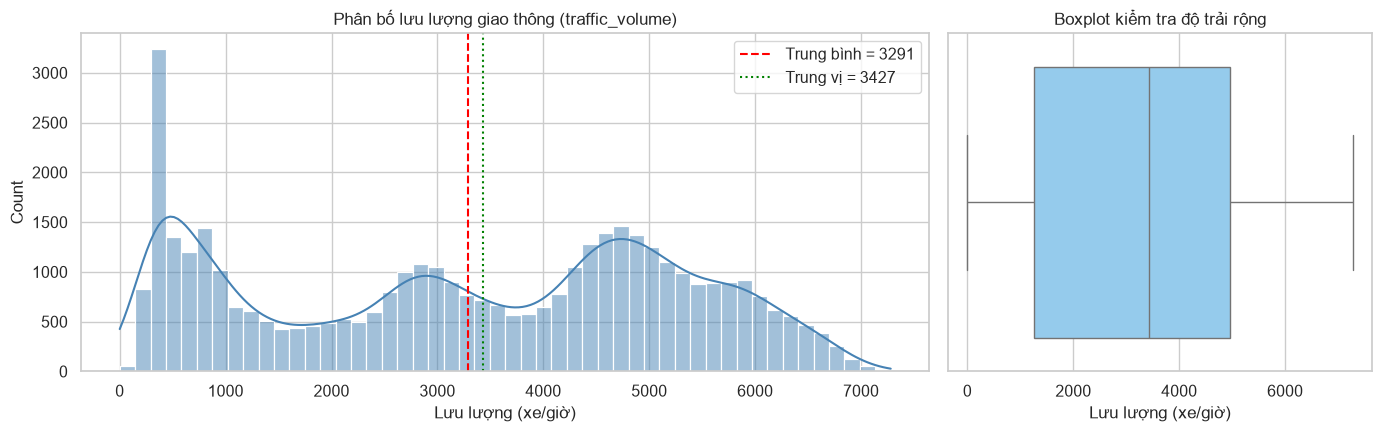

In [7]:
# 7. Hình EDA 1: Phân bố của biến mục tiêu traffic_volume (Lưu ảnh vào results/)
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.05)

RESULTS_DIR = os.path.join("..", "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

def luu_hinh(fig, ten_file):
    duong_dan = os.path.join(RESULTS_DIR, ten_file)
    fig.savefig(duong_dan, dpi=200, bbox_inches="tight")
    print("Đã lưu ảnh:", duong_dan)

df_eda = df.sort_values("date_time").drop_duplicates(subset=["date_time"], keep="first").copy()
df_eda["hour"] = df_eda["date_time"].dt.hour
df_eda["day_of_week"] = df_eda["date_time"].dt.dayofweek
df_eda["is_weekend"] = (df_eda["day_of_week"] >= 5).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})
sns.histplot(df_eda["traffic_volume"], bins=50, kde=True, color="steelblue", ax=axes[0])
axes[0].axvline(df_eda["traffic_volume"].mean(), color="red", linestyle="--", label=f"Trung bình = {df_eda['traffic_volume'].mean():.0f}")
axes[0].axvline(df_eda["traffic_volume"].median(), color="green", linestyle=":", label=f"Trung vị = {df_eda['traffic_volume'].median():.0f}")
axes[0].set_title("Phân bố lưu lượng giao thông (traffic_volume)")
axes[0].set_xlabel("Lưu lượng (xe/giờ)")
axes[0].legend()

sns.boxplot(x=df_eda["traffic_volume"], color="lightskyblue", ax=axes[1])
axes[1].set_title("Boxplot kiểm tra độ trải rộng")
axes[1].set_xlabel("Lưu lượng (xe/giờ)")
plt.tight_layout()

luu_hinh(fig, "fig_eda1_distribution.png")
plt.show()

Đã lưu ảnh: ..\results\fig_eda2_hourly_weekday_weekend.png


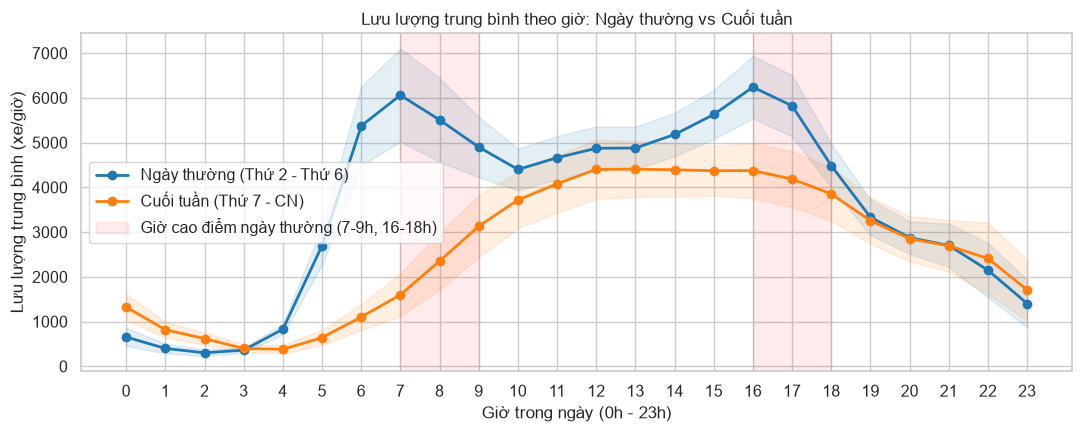

In [8]:
# 8. Hình EDA 2: Lưu lượng trung bình theo giờ - Ngày thường vs Cuối tuần (Lưu ảnh vào results/)
theo_gio = df_eda.groupby(["is_weekend", "hour"])["traffic_volume"].agg(["mean", "std"]).reset_index()

fig, ax = plt.subplots(figsize=(11, 4.5))
for wk, nhan, mau in [(0, "Ngày thường (Thứ 2 - Thứ 6)", "#1f77b4"), (1, "Cuối tuần (Thứ 7 - CN)", "#ff7f0e")]:
    d = theo_gio[theo_gio["is_weekend"] == wk]
    ax.plot(d["hour"], d["mean"], marker="o", label=nhan, color=mau, linewidth=2)
    ax.fill_between(d["hour"], d["mean"] - d["std"], d["mean"] + d["std"], alpha=0.12, color=mau)

ax.axvspan(7, 9, color="red", alpha=0.08, label="Giờ cao điểm ngày thường (7-9h, 16-18h)")
ax.axvspan(16, 18, color="red", alpha=0.08)
ax.set_xticks(range(0, 24))
ax.set_title("Lưu lượng trung bình theo giờ: Ngày thường vs Cuối tuần")
ax.set_xlabel("Giờ trong ngày (0h - 23h)")
ax.set_ylabel("Lưu lượng trung bình (xe/giờ)")
ax.legend()
plt.tight_layout()

luu_hinh(fig, "fig_eda2_hourly_weekday_weekend.png")
plt.show()

Đã lưu ảnh: ..\results\fig_eda3_weather_holiday.png


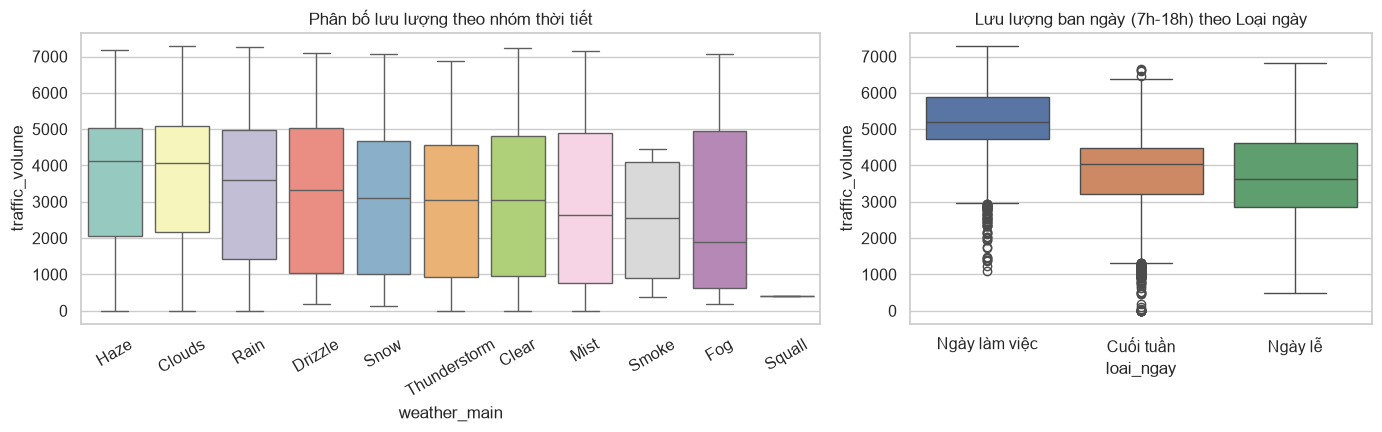

In [9]:
# 9. Hình EDA 3: Ảnh hưởng của Thời tiết & Ngày lễ đến lưu lượng (Lưu ảnh vào results/)
holiday_days_eda = set(df.loc[df["holiday"].notna(), "date_time"].dt.normalize())
df_eda["is_holiday"] = df_eda["date_time"].dt.normalize().isin(holiday_days_eda).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
thu_tu = df_eda.groupby("weather_main")["traffic_volume"].median().sort_values(ascending=False).index
sns.boxplot(data=df_eda, x="weather_main", y="traffic_volume", order=thu_tu, palette="Set3", ax=axes[0])
axes[0].set_title("Phân bố lưu lượng theo nhóm thời tiết")
axes[0].tick_params(axis="x", rotation=30)

ban_ngay = df_eda[df_eda["hour"].between(7, 18)].copy()
ban_ngay["loai_ngay"] = np.where(ban_ngay["is_holiday"] == 1, "Ngày lễ",
                        np.where(ban_ngay["is_weekend"] == 1, "Cuối tuần", "Ngày làm việc"))
sns.boxplot(data=ban_ngay, x="loai_ngay", y="traffic_volume", palette=["#4c72b0", "#dd8452", "#55a868"], ax=axes[1])
axes[1].set_title("Lưu lượng ban ngày (7h-18h) theo Loại ngày")
plt.tight_layout()

luu_hinh(fig, "fig_eda3_weather_holiday.png")
plt.show()

Đã lưu ảnh: ..\results\fig_eda4_heatmap_day_hour.png


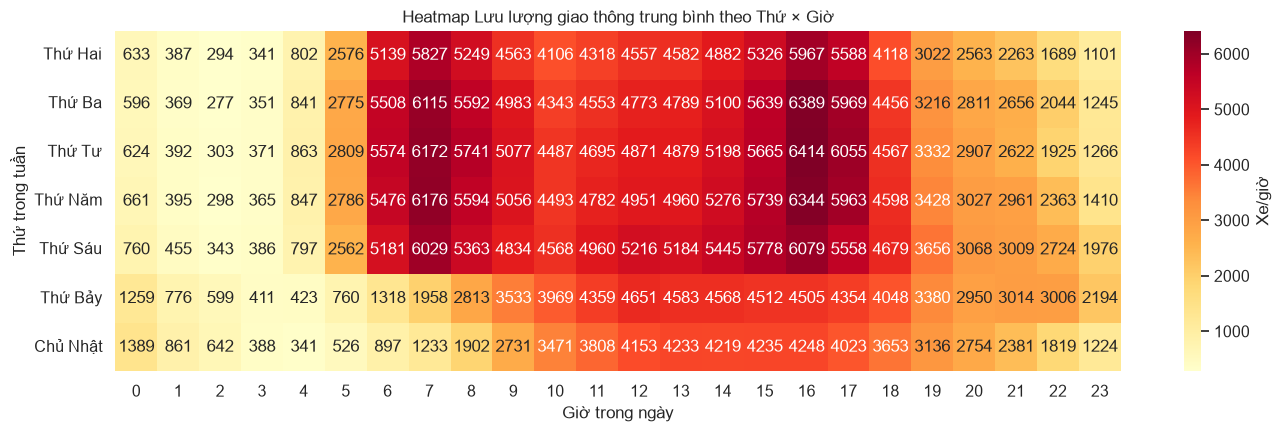

In [10]:
# 10. Hình EDA 4: Heatmap Lưu lượng giao thông trung bình theo Thứ × Giờ (Lưu ảnh vào results/)
TEN_THU = ["Thứ Hai", "Thứ Ba", "Thứ Tư", "Thứ Năm", "Thứ Sáu", "Thứ Bảy", "Chủ Nhật"]
bang_nhiet = df_eda.pivot_table(index="day_of_week", columns="hour", values="traffic_volume", aggfunc="mean")
bang_nhiet.index = TEN_THU

fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(bang_nhiet, cmap="YlOrRd", annot=True, fmt=".0f", cbar_kws={"label": "Xe/giờ"}, ax=ax)
ax.set_title("Heatmap Lưu lượng giao thông trung bình theo Thứ × Giờ")
ax.set_xlabel("Giờ trong ngày")
ax.set_ylabel("Thứ trong tuần")
plt.tight_layout()

luu_hinh(fig, "fig_eda4_heatmap_day_hour.png")
plt.show()